# Explanation Fidelity Degradation in Sequential Multi-Agent AI Pipelines
### Full reproducible implementation (Google Colab)

This notebook reproduces every result, table, and figure reported in the paper *"Explanation Fidelity Degradation in Sequential Multi-Agent AI Pipelines: A Synthetic Benchmark and Quantitative Framework for Cross-Hop Information Loss."*

**How to use this notebook in Google Colab:**
1. Upload this file to Colab (File → Upload notebook), or open directly from GitHub/Drive.
2. Run all cells in order (Runtime → Run all). No external API keys or GPU are required — everything runs on Colab's free CPU tier in under a minute.
3. All figures and tables will render inline below their corresponding cells.

**Pipeline overview:** a synthetic 5-class text classification benchmark with known ground-truth signal words → a 3-hop agentic pipeline (TF-IDF retrieval → mutual-information feature selection → logistic regression classification) → fidelity, consistency, faithfulness, and accuracy metrics, benchmarked against a non-chained single-agent baseline.

In [1]:
# Colab already includes scikit-learn, scipy, numpy, pandas, and matplotlib.
# This cell ensures they're present without erroring if run in a restricted environment.
try:
    import sklearn, scipy, numpy, pandas, matplotlib
except ImportError:
    %pip install -q scikit-learn scipy numpy pandas matplotlib

import warnings
warnings.filterwarnings("ignore")  # hides a scikit-learn UserWarning from mutual_info_classif (sparse input is treated as discrete, see README, Known issue)

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import LabelEncoder
from scipy import stats
import matplotlib.pyplot as plt

print("All libraries loaded successfully.")

All libraries loaded successfully.


## 1. Synthetic Benchmark Generation

We construct a synthetic 5-class text classification benchmark where each class has 12 known "signal" words embedded probabilistically, alongside shared background noise vocabulary and a small rate of cross-class signal leakage. This gives us **ground-truth informative features per document** — essential for objectively measuring explanation fidelity, which real-world corpora cannot provide.

In [2]:
rng = np.random.default_rng(42)

CLASSES = ["technology", "sports", "health", "finance", "education"]

SIGNAL_WORDS = {
    "technology": ["algorithm","software","processor","network","database","encryption",
                   "server","bandwidth","firmware","compiler","semiconductor","interface"],
    "sports": ["tournament","striker","referee","stadium","athlete","scoreboard",
               "midfielder","championship","sprint","dribble","goalpost","relay"],
    "health": ["diagnosis","antibody","symptom","vaccine","clinician","dosage",
               "pathogen","therapy","biopsy","cardiac","immunity","prescription"],
    "finance": ["dividend","portfolio","interest","equity","liquidity","inflation",
                "hedge","valuation","amortize","treasury","leverage","yield"],
    "education": ["curriculum","pedagogy","assessment","syllabus","tutor","semester",
                  "literacy","enrollment","scholarship","classroom","rubric","thesis"],
}

NOISE_POOL = [f"word{i}" for i in range(150)]
N_PER_CLASS = 300
SIGNAL_PROB = 0.55
NOISE_MIN, NOISE_MAX = 15, 40

def generate_document(cls):
    tokens = []
    for w in SIGNAL_WORDS[cls]:
        if rng.random() < SIGNAL_PROB:
            reps = rng.integers(1, 3)
            tokens.extend([w] * reps)
    for other_cls in CLASSES:
        if other_cls == cls:
            continue
        for w in SIGNAL_WORDS[other_cls]:
            if rng.random() < 0.04:
                tokens.append(w)
    n_noise = rng.integers(NOISE_MIN, NOISE_MAX)
    tokens.extend(rng.choice(NOISE_POOL, size=n_noise).tolist())
    rng.shuffle(tokens)
    return " ".join(tokens)

docs, labels = [], []
for cls in CLASSES:
    for _ in range(N_PER_CLASS):
        docs.append(generate_document(cls))
        labels.append(cls)

idx = rng.permutation(len(docs))
docs = [docs[i] for i in idx]
labels = [labels[i] for i in idx]

print(f"Generated {len(docs)} documents across {len(CLASSES)} classes.")
print(f"Example document: {docs[0][:100]}...")
print(f"Example label: {labels[0]}")

Generated 1500 documents across 5 classes.
Example document: word131 word116 symptom word18 word4 word134 word108 word34 antibody word148 dosage word14 diagnosis...
Example label: health


## 2. Three-Hop Agentic Pipeline

- **Hop 1 (Retriever agent):** TF-IDF top-8 term retrieval per document.
- **Hop 2 (Feature-selector agent):** mutual-information-based global filtering to the top-60 features, operating only on what Hop 1 retrieved.
- **Hop 3 (Classifier agent):** logistic regression trained only on the Hop-2-selected features, explained via linear attribution.
- **Baseline:** a non-chained logistic regression trained directly on the full TF-IDF space, for comparison.

**Note on Hop 2:** `mutual_info_classif` receives a sparse TF-IDF matrix, and scikit-learn treats sparse input as discrete (`discrete_features="auto"`). The results below depend on this. The repository README (Known issue) and `sensitivity_mutual_info.py` show what happens with a continuous estimator or chi-squared.

In [3]:
label_to_signal = {c: set(SIGNAL_WORDS[c]) for c in CLASSES}

X_train_docs, X_test_docs, y_train, y_test = train_test_split(
    docs, labels, test_size=0.30, random_state=42, stratify=labels
)

vectorizer = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b")
X_train_full = vectorizer.fit_transform(X_train_docs)
X_test_full = vectorizer.transform(X_test_docs)
vocab = np.array(vectorizer.get_feature_names_out())
vocab_index = {w: i for i, w in enumerate(vocab)}

def topk_terms_for_row(csr_row, k):
    row = csr_row.toarray().ravel()
    if np.all(row == 0):
        return set()
    top_idx = np.argsort(row)[::-1][:k]
    top_idx = [i for i in top_idx if row[i] > 0]
    return set(vocab[top_idx])

TOP_K, TOP_M = 8, 60

# Hop 1: Retriever
E1_train = [topk_terms_for_row(X_train_full[i], TOP_K) for i in range(X_train_full.shape[0])]
E1_test = [topk_terms_for_row(X_test_full[i], TOP_K) for i in range(X_test_full.shape[0])]

def fidelity_at_k(explanation_sets, y_true_labels):
    scores = []
    for expl, lab in zip(explanation_sets, y_true_labels):
        if len(expl) == 0:
            scores.append(0.0); continue
        hits = len(expl & label_to_signal[lab])
        scores.append(hits / len(expl))
    return np.array(scores)

fid_hop1 = fidelity_at_k(E1_test, y_test)
print(f"Hop 1 mean fidelity: {fid_hop1.mean():.3f} (SD = {fid_hop1.std():.3f})")

Hop 1 mean fidelity: 0.595 (SD = 0.163)


In [4]:
# Hop 2: Feature-Selector
retrieved_vocab = sorted(set().union(*E1_train))
retrieved_idx = [vocab_index[w] for w in retrieved_vocab if w in vocab_index]
retrieved_terms = vocab[retrieved_idx]

X_train_retrieved = X_train_full[:, retrieved_idx]
X_test_retrieved = X_test_full[:, retrieved_idx]

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
mi_scores = mutual_info_classif(X_train_retrieved, y_train_enc, random_state=42)
top_m_local_idx = np.argsort(mi_scores)[::-1][:TOP_M]
selected_terms = set(retrieved_terms[top_m_local_idx])
global_select_idx = [retrieved_idx[i] for i in top_m_local_idx]

E2_test = [expl & selected_terms for expl in E1_test]
fid_hop2 = fidelity_at_k(E2_test, y_test)
consistency_1_2 = np.array([len(e1 & e2)/len(e1) if len(e1) > 0 else 0.0 for e1, e2 in zip(E1_test, E2_test)])
print(f"Hop 2 mean fidelity: {fid_hop2.mean():.3f} (SD = {fid_hop2.std():.3f})")
print(f"Hop 1->2 consistency: {consistency_1_2.mean():.3f}")

Hop 2 mean fidelity: 0.202 (SD = 0.362)
Hop 1->2 consistency: 0.137


In [5]:
# Hop 3: Classifier
X_train_final = X_train_full[:, global_select_idx]
X_test_final = X_test_full[:, global_select_idx]
final_terms = vocab[global_select_idx]

clf_chained = LogisticRegression(max_iter=2000, random_state=42)
clf_chained.fit(X_train_final, y_train)
y_pred_chained = clf_chained.predict(X_test_final)
acc_chained = accuracy_score(y_test, y_pred_chained)
f1_chained = f1_score(y_test, y_pred_chained, average="macro")

class_order = clf_chained.classes_
X_test_final_dense = X_test_final.toarray()
pred_class_indices = [list(class_order).index(p) for p in y_pred_chained]

def linear_explanation(clf, X_row_dense, terms, k, predicted_class_idx):
    coefs = clf.coef_[predicted_class_idx]
    attributions = coefs * X_row_dense
    if np.all(attributions == 0):
        return set()
    top_idx = np.argsort(np.abs(attributions))[::-1][:k]
    top_idx = [i for i in top_idx if attributions[i] != 0]
    return set(terms[top_idx])

E3_test = [linear_explanation(clf_chained, X_test_final_dense[i], final_terms, TOP_K, pred_class_indices[i])
           for i in range(X_test_final_dense.shape[0])]

fid_hop3 = fidelity_at_k(E3_test, y_test)
consistency_2_3 = np.array([len(e2 & e3)/len(e2) if len(e2) > 0 else 0.0 for e2, e3 in zip(E2_test, E3_test)])
consistency_1_3 = np.array([len(e1 & e3)/len(e1) if len(e1) > 0 else 0.0 for e1, e3 in zip(E1_test, E3_test)])

print(f"Hop 3 mean fidelity: {fid_hop3.mean():.3f} (SD = {fid_hop3.std():.3f})")
print(f"Chained accuracy: {acc_chained:.3f}, macro-F1: {f1_chained:.3f}")

Hop 3 mean fidelity: 0.090 (SD = 0.111)
Chained accuracy: 0.620, macro-F1: 0.631


In [6]:
# Non-chained single-agent baseline
clf_baseline = LogisticRegression(max_iter=2000, random_state=42)
clf_baseline.fit(X_train_full, y_train)
y_pred_baseline = clf_baseline.predict(X_test_full)
acc_baseline = accuracy_score(y_test, y_pred_baseline)
f1_baseline = f1_score(y_test, y_pred_baseline, average="macro")

class_order_b = clf_baseline.classes_
pred_class_indices_b = [list(class_order_b).index(p) for p in y_pred_baseline]
X_test_full_dense = X_test_full.toarray()

E_base_test = [linear_explanation(clf_baseline, X_test_full_dense[i], vocab, TOP_K, pred_class_indices_b[i])
               for i in range(X_test_full_dense.shape[0])]
fid_baseline = fidelity_at_k(E_base_test, y_test)

def faithfulness_deletion(clf, X_row_dense, terms, explanation, predicted_class_idx):
    if len(explanation) == 0:
        return 0.0
    base_prob = clf.predict_proba(X_row_dense.reshape(1, -1))[0][predicted_class_idx]
    modified = X_row_dense.copy()
    term_idx = [i for i, t in enumerate(terms) if t in explanation]
    modified[term_idx] = 0.0
    new_prob = clf.predict_proba(modified.reshape(1, -1))[0][predicted_class_idx]
    return base_prob - new_prob

faith_hop3 = np.array([faithfulness_deletion(clf_chained, X_test_final_dense[i], final_terms, E3_test[i], pred_class_indices[i])
                        for i in range(X_test_final_dense.shape[0])])
faith_baseline = np.array([faithfulness_deletion(clf_baseline, X_test_full_dense[i], vocab, E_base_test[i], pred_class_indices_b[i])
                            for i in range(X_test_full_dense.shape[0])])

print(f"Baseline mean fidelity: {fid_baseline.mean():.3f} (SD = {fid_baseline.std():.3f})")
print(f"Chained faithfulness: {faith_hop3.mean():.3f}, Baseline faithfulness: {faith_baseline.mean():.3f}")
print(f"Baseline accuracy: {acc_baseline:.3f}, macro-F1: {f1_baseline:.3f}")

Baseline mean fidelity: 0.797 (SD = 0.173)
Chained faithfulness: 0.240, Baseline faithfulness: 0.684
Baseline accuracy: 1.000, macro-F1: 1.000


## 3. Statistical Significance Testing

Paired t-tests compare fidelity across hops (within-subject); independent t-tests compare the chained pipeline against the baseline.

In [7]:
t_12, p_12 = stats.ttest_rel(fid_hop1, fid_hop2)
t_23, p_23 = stats.ttest_rel(fid_hop2, fid_hop3)
t_13, p_13 = stats.ttest_rel(fid_hop1, fid_hop3)
t_base_chain, p_base_chain = stats.ttest_ind(fid_baseline, fid_hop3)
t_faith, p_faith = stats.ttest_ind(faith_baseline, faith_hop3)

results_summary = pd.DataFrame({
    "Comparison": ["Hop1 vs Hop2", "Hop2 vs Hop3", "Hop1 vs Hop3", "Baseline vs Chained (fidelity)", "Baseline vs Chained (faithfulness)"],
    "t-statistic": [t_12, t_23, t_13, t_base_chain, t_faith],
    "p-value": [p_12, p_23, p_13, p_base_chain, p_faith],
})
results_summary["p-value"] = results_summary["p-value"].apply(lambda x: "< .001" if x < 0.001 else f"{x:.3f}")
results_summary

,Comparison,t-statistic,p-value
0,Hop1 vs Hop2,21.913802,< .001
1,Hop2 vs Hop3,7.771889,< .001
2,Hop1 vs Hop3,51.846774,< .001
3,Baseline vs Chained (fidelity),72.713252,< .001
4,Baseline vs Chained (faithfulness),33.716656,< .001


## 4. Results Table (Table 1 in the paper)

In [8]:
table1 = pd.DataFrame({
    "Stage": ["Hop 1 - Retriever", "Hop 2 - Feature-Selector", "Hop 3 - Classifier", "Baseline (non-chained)"],
    "Mean Fidelity": [fid_hop1.mean(), fid_hop2.mean(), fid_hop3.mean(), fid_baseline.mean()],
    "SD": [fid_hop1.std(), fid_hop2.std(), fid_hop3.std(), fid_baseline.std()],
    "Consistency from Prior Hop": [np.nan, consistency_1_2.mean(), consistency_2_3.mean(), np.nan],
    "n": [len(y_test)] * 4,
}).round(3)
table1

,Stage,Mean Fidelity,SD,Consistency from Prior Hop,n
0,Hop 1 - Retriever,0.595,0.163,NaN,450
1,Hop 2 - Feature-Selector,0.202,0.362,0.137,450
2,Hop 3 - Classifier,0.090,0.111,0.593,450
3,Baseline (non-chained),0.797,0.173,NaN,450


## 5. Figures

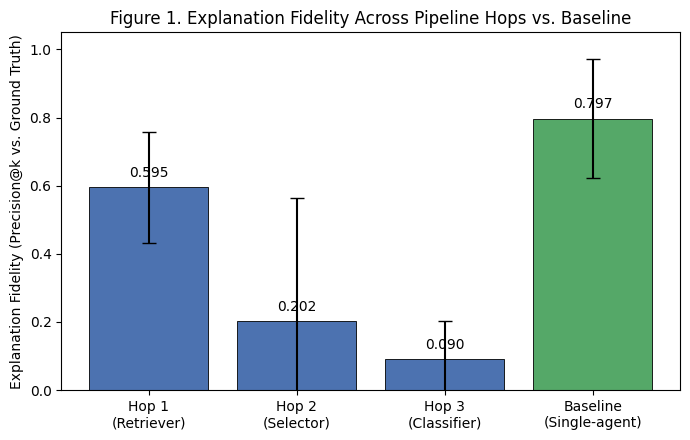

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
stages = ["Hop 1\n(Retriever)", "Hop 2\n(Selector)", "Hop 3\n(Classifier)", "Baseline\n(Single-agent)"]
means = [fid_hop1.mean(), fid_hop2.mean(), fid_hop3.mean(), fid_baseline.mean()]
stds = [fid_hop1.std(), fid_hop2.std(), fid_hop3.std(), fid_baseline.std()]
colors = ["#4C72B0", "#4C72B0", "#4C72B0", "#55A868"]
bars = ax.bar(stages, means, yerr=stds, capsize=5, color=colors, edgecolor="black", linewidth=0.6)
ax.set_ylabel("Explanation Fidelity (Precision@k vs. Ground Truth)")
ax.set_title("Figure 1. Explanation Fidelity Across Pipeline Hops vs. Baseline")
ax.set_ylim(0, 1.05)
for bar, m in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width()/2, m + 0.03, f"{m:.3f}", ha="center", fontsize=10)
plt.tight_layout()
plt.show()

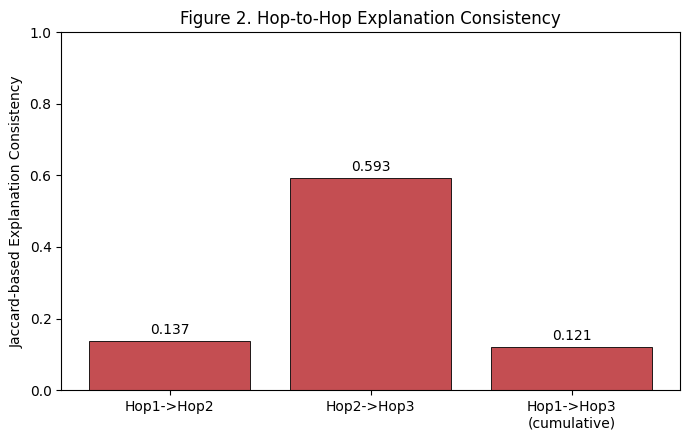

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
pairs = ["Hop1->Hop2", "Hop2->Hop3", "Hop1->Hop3\n(cumulative)"]
cvals = [consistency_1_2.mean(), consistency_2_3.mean(), consistency_1_3.mean()]
bars = ax.bar(pairs, cvals, color="#C44E52", edgecolor="black", linewidth=0.6)
ax.set_ylabel("Jaccard-based Explanation Consistency")
ax.set_title("Figure 2. Hop-to-Hop Explanation Consistency")
ax.set_ylim(0, 1.0)
for bar, v in zip(bars, cvals):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.02, f"{v:.3f}", ha="center", fontsize=10)
plt.tight_layout()
plt.show()

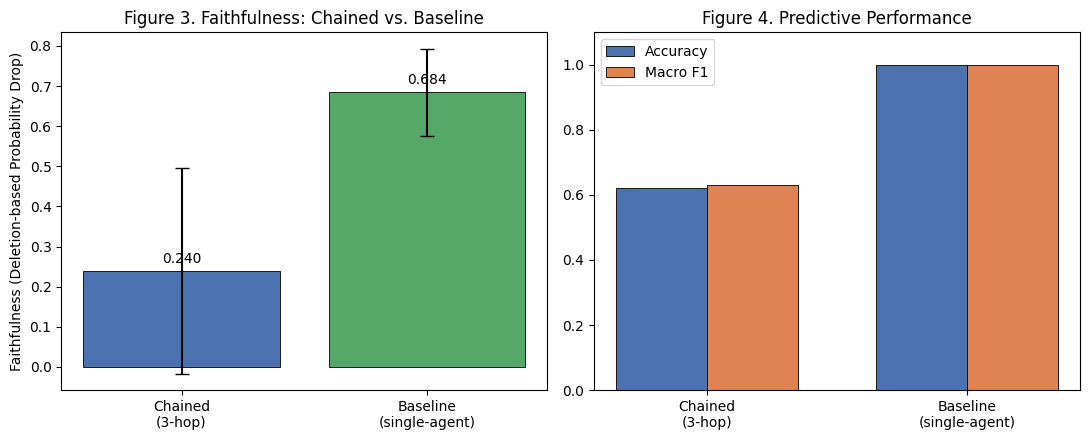

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

labels_f = ["Chained\n(3-hop)", "Baseline\n(single-agent)"]
fvals = [faith_hop3.mean(), faith_baseline.mean()]
fstds = [faith_hop3.std(), faith_baseline.std()]
axes[0].bar(labels_f, fvals, yerr=fstds, capsize=5, color=["#4C72B0", "#55A868"], edgecolor="black", linewidth=0.6)
axes[0].set_ylabel("Faithfulness (Deletion-based Probability Drop)")
axes[0].set_title("Figure 3. Faithfulness: Chained vs. Baseline")
for i, v in enumerate(fvals):
    axes[0].text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=10)

x = np.arange(2)
width = 0.35
accs = [acc_chained, acc_baseline]
f1s = [f1_chained, f1_baseline]
axes[1].bar(x - width/2, accs, width, label="Accuracy", color="#4C72B0", edgecolor="black", linewidth=0.6)
axes[1].bar(x + width/2, f1s, width, label="Macro F1", color="#DD8452", edgecolor="black", linewidth=0.6)
axes[1].set_xticks(x); axes[1].set_xticklabels(labels_f)
axes[1].set_title("Figure 4. Predictive Performance")
axes[1].legend(); axes[1].set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

## 6. Summary

This notebook reproduces the paper's central finding: explanation fidelity collapses from **{:.3f}** (Hop 1) to **{:.3f}** (Hop 2) to **{:.3f}** (Hop 3), compared with **{:.3f}** for the non-chained baseline — all differences statistically significant at p < .001. Faithfulness and predictive accuracy show the same pattern.

Re-running this notebook (Runtime → Run all) with the same random seed will reproduce these exact numbers every time.